# MTA Data Series 2026 · Las Vegas GP Driver Selection (XGBoost)

**Task:** pick exactly 3 drivers for the 2026 Las Vegas Grand Prix to maximize the **point-to-cost ratio = Σ points ÷ Σ price**.

**Approach:** predict each driver's expected points with XGBoost (pre-race features only), divide by price, then score all 1,330 three-driver lineups.

## Step 1 · Data Acquisition
Import packages and read the 13 competition files.

In [1]:
# Requirements: pip install -r requirements.txt
import os, zipfile, itertools
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Folder with the 13 competition CSVs (not included in this repo, see data/README.md).
# Override with the MTA_DATA_DIR environment variable.
DATA_DIR = os.environ.get("MTA_DATA_DIR", "../data/datasets")
if not os.path.exists(DATA_DIR):
    try:                                   # on Google Colab: upload MTA_DA_Datasets.zip once
        from google.colab import files
        zipfile.ZipFile(next(iter(files.upload()))).extractall("/content")
        DATA_DIR = "/content/datasets"
    except ImportError:
        raise FileNotFoundError(f"Put the competition CSVs in {DATA_DIR} (see data/README.md)")

LAST_DONE_RACE_ID = 1188   # 2026 São Paulo GP, the last race with results
VEGAS_RACE_ID = 1189       # 2026 Las Vegas GP, the race we predict
print("Files:", sorted(os.listdir(DATA_DIR)))


Files: ['circuits.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'prices.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'sprint_results.csv', 'status.csv']


In [2]:
NA = ["\\N", "NULL"]                               # how missing values are written in the files
names = ["results", "races", "drivers", "constructors", "status", "prices", "qualifying",
         "lap_times", "pit_stops", "driver_standings", "circuits", "constructor_standings", "sprint_results"]
data = {n: pd.read_csv(f"{DATA_DIR}/{n}.csv", na_values=NA) for n in names}

res = data["results"]; races = data["races"]; drivers = data["drivers"]; prices = data["prices"]
status = data["status"]; qual = data["qualifying"]; laps = data["lap_times"]
pits = data["pit_stops"]; standings = data["driver_standings"]
# sprint_results is NOT used: the case covers main races only

print("Loaded shapes:")
for n, d in data.items():
    print(f"  {n:<22} {d.shape}")
print("Seasons:", races.year.min(), "->", races.year.max(), "| races with results:", res.raceId.nunique())

Loaded shapes:
  results                (27678, 19)
  races                  (1172, 19)
  drivers                (22, 10)
  constructors           (214, 6)
  status                 (141, 3)
  prices                 (21, 6)
  qualifying             (11408, 10)
  lap_times              (639277, 7)
  pit_stops              (13029, 8)
  driver_standings       (35813, 8)
  circuits               (78, 10)
  constructor_standings  (220, 8)
  sprint_results         (612, 17)
Seasons: 1950 -> 2026 | races with results: 1169


## Step 1 · Data Type & Missing Value Check

In [3]:
def profile(df, name):
    out = pd.DataFrame({"dtype": df.dtypes.astype(str),
                        "missing": df.isna().sum(),
                        "missing %": (df.isna().mean() * 100).round(1)})
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    return out

display(profile(res, "results"))
display(profile(qual, "qualifying"))
display(profile(prices, "prices"))

results: 27,678 rows x 19 columns


,dtype,missing,missing %
resultId,int64,0,0.0
raceId,int64,0,0.0
driverId,int64,0,0.0
constructorId,int64,0,0.0
number,float64,6,0.0
grid,int64,0,0.0
position,float64,10953,39.6
positionText,str,0,0.0
positionOrder,int64,0,0.0
points,float64,0,0.0


qualifying: 11,408 rows x 10 columns


,dtype,missing,missing %
qualifyId,int64,0,0.0
raceId,int64,0,0.0
driverId,int64,0,0.0
constructorId,int64,0,0.0
number,int64,0,0.0
position,int64,0,0.0
q1,str,186,1.6
q2,str,4911,43.0
q3,str,7359,64.5
source,str,0,0.0


prices: 21 rows x 6 columns


,dtype,missing,missing %
driverId,int64,0,0.0
price,int64,0,0.0
driverRef,str,0,0.0
number,int64,0,0.0
forename,str,0,0.0
surname,str,0,0.0


## Step 1 · Data Cleaning (1/2)
Check 1: driver numbers · Check 2: finishing status

In [4]:
# Check 1: driver numbers don't match between files -> join every table on driverId
last_race = res[res.raceId == LAST_DONE_RACE_ID][["driverId", "number"]].rename(columns={"number": "number_in_results"})
chk = prices[["driverId", "surname", "number"]].rename(columns={"number": "number_in_prices"})
chk = chk.merge(last_race, on="driverId")
print("Check 1 · drivers whose number differs between files:")
print(chk[chk.number_in_prices != chk.number_in_results].to_string(index=False))

# Check 2: finishing status is written in many ways -> classified = numeric positionText
labels = res.merge(status, on="statusId").status
print("\nCheck 2 · distinct status labels:", labels.nunique())
print(labels.value_counts().head(6).to_string())
classified = res.positionText.astype(str).str.isdigit()      # numeric position = finished
res["dnf"] = (~classified).astype(int)                        # R / W / D = did not finish
print("DNF rows:", res.dnf.sum(), "of", len(res))

Check 1 · drivers whose number differs between files:
 driverId    surname  number_in_prices  number_in_results
      830 Verstappen                33                3.0
      846     Norris                 4                1.0
      860    Bearman                38               87.0

Check 2 · distinct status labels: 139
status
Finished           8227
+1 Lap             4037
Engine             2026
+2 Laps            1613
Accident           1062
Did not qualify    1025
DNF rows: 11087 of 27678


## Step 1 · Data Cleaning (2/2)
Check 3: points rules · Check 4: outliers · Check 5: missing prices

In [5]:
# Check 3: points rules changed over time -> re-score every race with 2026 rules
PTS = np.array([25, 18, 15, 12, 10, 8, 6, 4, 2, 1] + [0] * 40, dtype=float)
res["y"] = np.where(classified, PTS[(res.positionOrder - 1).clip(0, 49)], 0.0)
y24 = res.merge(races[["raceId", "year"]], on="raceId").query("year == 2024")
print("Check 3 · 2024 rows re-scored:", (y24.points != y24.y).sum(), "of", len(y24))

# Check 4: pit stop outliers (red-flag stoppages) -> remove stops over 40 seconds
print("Check 4 · longest pit stop:", round(pits.milliseconds.max() / 60000, 1), "minutes")
print("         stops over 40 s removed:", (pits.milliseconds >= 40000).sum(), "of", len(pits))
pits = pits[pits.milliseconds < 40000]

# Check 5: drivers racing in 2026 with no price -> cannot be selected
in_2026 = res[res.raceId == LAST_DONE_RACE_ID].driverId
no_price = drivers[drivers.driverId.isin(in_2026) & ~drivers.driverId.isin(prices.driverId)]
print("Check 5 · racing in 2026 but no price:", list(no_price.forename + " " + no_price.surname))

Check 3 · 2024 rows re-scored: 19 of 479
Check 4 · longest pit stop: 51.2 minutes
         stops over 40 s removed: 766 of 13029
Check 5 · racing in 2026 but no price: ['Rafael Camara']


## Step 1 · Data Imputation

In [6]:
races = races.sort_values(["date", "raceId"]).copy()
races["seq"] = range(len(races))                               # race order in time
race_info = races[["raceId", "year", "round", "circuitId", "seq"]]
res = res.merge(race_info, on="raceId")

# 1) grid = 0 means a pit-lane start -> place the driver at the back of the grid
print("Pit-lane starts (grid = 0):", (res.grid == 0).sum())
res["grid"] = res.grid.replace(0, np.nan)
res["grid"] = res.grid.fillna(res.groupby("raceId").grid.transform("max") + 1)
print("Missing grid after imputation:", res.grid.isna().sum())

# 2) qualifying best lap: q1 / q2 / q3 text -> seconds; take the fastest; gap to pole in %
def best_lap(row):
    t = [int(v.split(":")[0]) * 60 + float(v.split(":")[1]) for v in row if isinstance(v, str) and ":" in v]
    return min(t) if t else np.nan
qual["best"] = [best_lap(x) for x in qual[["q1", "q2", "q3"]].itertuples(index=False)]
qual["qgap"] = qual.best / qual.groupby("raceId").best.transform("min") - 1
print("Qualifying rows with a lap time:", qual.best.notna().sum(), "of", len(qual))

# 3) other blanks (e.g. a rookie's history) are left as NaN on purpose: XGBoost handles them natively

Pit-lane starts (grid = 0): 1638
Missing grid after imputation: 0
Qualifying rows with a lap time: 11222 of 11408


## Step 2 · Organizing the Data: Long Format
Stack qualifying and race rows, with a `session` column.

In [7]:
# add a 'session' column to both and align columns
race_long = res[["resultId", "raceId", "driverId", "constructorId", "year", "round", "circuitId", "seq",
                 "grid", "positionOrder", "dnf", "y"]].copy()
race_long["session"] = "race"
qual_long = qual[["raceId", "driverId", "constructorId", "position", "qgap"]].drop_duplicates(["raceId", "driverId"]).copy()
qual_long["session"] = "qual"

long_df = pd.concat([race_long, qual_long], ignore_index=True)
long_df = long_df.sort_values(["raceId", "driverId", "session"]).reset_index(drop=True)
long_df = long_df[["raceId", "driverId", "session"] + [c for c in long_df.columns if c not in ("raceId", "driverId", "session")]]

print("Long dataset shape:", long_df.shape)
display(long_df[long_df.raceId == LAST_DONE_RACE_ID].head(6))

Long dataset shape: (39086, 15)


,raceId,driverId,session,resultId,constructorId,year,round,circuitId,seq,grid,positionOrder,dnf,y,position,qgap
39042,1188,1,qual,NaN,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,0.037535
39043,1188,1,race,27670.0,6,2026.0,20.0,18.0,1168.0,20.0,9.0,0.0,2.0,NaN,NaN
39044,1188,4,qual,NaN,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,0.026826
39045,1188,4,race,27673.0,117,2026.0,20.0,18.0,1168.0,8.0,12.0,0.0,0.0,NaN,NaN
39046,1188,807,qual,NaN,216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,0.018629
39047,1188,807,race,27671.0,216,2026.0,20.0,18.0,1168.0,4.0,10.0,0.0,1.0,NaN,NaN


In [8]:
# other raw tables are also long: one row per lap / per pit stop
print("lap_times:", laps.shape, "-> one row per lap")
print("pit_stops:", pits.shape, "-> one row per pit stop")

# aggregate them to one row per driver per race
med = laps.groupby(["raceId", "driverId"]).milliseconds.median().rename("med").reset_index()
med["lapgap"] = med.med / med.groupby("raceId").med.transform("median") - 1     # race pace vs field
pit = pits.groupby(["raceId", "driverId"]).milliseconds.median().rename("pit_ms").reset_index()
st = standings[["raceId", "driverId", "position"]].rename(columns={"position": "stand_pos"})
st = st.drop_duplicates(["raceId", "driverId"])

print(f"{len(laps):,} laps -> {len(med):,} driver-races")
print(f"{len(pits):,} pit stops -> {len(pit):,} driver-races")

lap_times: (639277, 7) -> one row per lap
pit_stops: (12262, 8) -> one row per pit stop


639,277 laps -> 11,935 driver-races
12,262 pit stops -> 6,355 driver-races


## Step 3 · Organizing the Data: Wide Format
One row = one driver in one race: features + label.

In [9]:
# split the long table by session, rename, then put qual and race side by side (same row)
race_rows = long_df[long_df.session == "race"].drop(columns=["session", "position", "qgap"])
race_rows = race_rows.sort_values("resultId")                # keep the original row order (reproducible results)
qual_rows = long_df[long_df.session == "qual"][["raceId", "driverId", "position", "qgap"]]
qual_rows = qual_rows.rename(columns={"position": "q_pos_hist"})

wide = race_rows.merge(qual_rows, on=["raceId", "driverId"], how="left").drop(columns="resultId")
for t in (pit, st, med[["raceId", "driverId", "lapgap"]]):
    wide = wide.merge(t, on=["raceId", "driverId"], how="left")

print("Wide dataset shape:", wide.shape)
display(wide[wide.raceId == LAST_DONE_RACE_ID].head(6))

Wide dataset shape: (27678, 16)


,raceId,driverId,constructorId,year,round,circuitId,seq,grid,positionOrder,dnf,y,q_pos_hist,qgap,pit_ms,stand_pos,lapgap
27656,1188,846,1,2026.0,20.0,18.0,1168.0,1.0,1.0,0.0,25.0,1.0,0.008358,23995.0,6.0,-0.029124
27657,1188,830,9,2026.0,20.0,18.0,1168.0,21.0,2.0,0.0,18.0,16.0,0.051795,23745.0,2.0,-0.018691
27658,1188,865,9,2026.0,20.0,18.0,1168.0,5.0,3.0,0.0,15.0,7.0,0.005453,23957.0,8.0,-0.022376
27659,1188,847,131,2026.0,20.0,18.0,1168.0,7.0,4.0,0.0,12.0,2.0,0.000000,24543.5,3.0,-0.008348
27660,1188,863,131,2026.0,20.0,18.0,1168.0,2.0,5.0,0.0,10.0,3.0,0.015563,24458.0,1.0,-0.013253
27661,1188,857,1,2026.0,20.0,18.0,1168.0,10.0,6.0,0.0,8.0,12.0,0.041778,24695.0,7.0,-0.005972


In [10]:
# add tonight's Las Vegas race: official grid (after 5 penalties) + qualifying order (before penalties)
code2id = drivers.set_index("code").driverId.to_dict()
GRID  = ["VER","RUS","NOR","HAD","LIN","ANT","LAW","GAS","COL","LEC","HAM",
         "HUL","BOR","ALB","CAM","PER","PIA","ALO","BOT","SAI","STR","BEA"]
QUALI = ["ANT","VER","RUS","NOR","HAD","LIN","PIA","LAW","GAS","COL","LEC",
         "HAM","HUL","SAI","BOR","ALB","CAM","PER","ALO","STR","BOT","BEA"]

team_now = wide[wide.raceId == LAST_DONE_RACE_ID].set_index("driverId").constructorId
vegas = pd.DataFrame({"driverId": [code2id[c] for c in GRID], "grid": range(1, 23)})
vegas["q_pos"] = vegas.driverId.map({code2id[c]: i + 1 for i, c in enumerate(QUALI)})
vegas = vegas.assign(raceId=VEGAS_RACE_ID, year=2026, round=21, circuitId=80,
                     seq=int(races.loc[races.raceId == VEGAS_RACE_ID, "seq"].iloc[0]),
                     constructorId=vegas.driverId.map(team_now))

r = pd.concat([wide, vegas], ignore_index=True)
r["q_pos"] = r.q_pos.fillna(r.q_pos_hist).fillna(r.grid)       # missing qualifying -> use grid
r = r.sort_values(["seq", "grid"]).reset_index(drop=True)
print("Las Vegas rows added:", (r.raceId == VEGAS_RACE_ID).sum(), "| final wide shape:", r.shape)
display(r[r.raceId == VEGAS_RACE_ID].head(6))

Las Vegas rows added: 22 | final wide shape: (27700, 17)


,raceId,driverId,constructorId,year,round,circuitId,seq,grid,positionOrder,dnf,y,q_pos_hist,qgap,pit_ms,stand_pos,lapgap,q_pos
27678,1189,830,9,2026.0,21.0,80.0,1169.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
27679,1189,847,131,2026.0,21.0,80.0,1169.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0
27680,1189,846,1,2026.0,21.0,80.0,1169.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0
27681,1189,865,9,2026.0,21.0,80.0,1169.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
27682,1189,876,215,2026.0,21.0,80.0,1169.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0
27683,1189,863,131,2026.0,21.0,80.0,1169.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


## Step 3 · Feature Engineering
Pre-race information only: every rolling feature uses `shift(1)` to avoid data leakage.

In [11]:
gd = r.groupby("driverId")
roll = lambda col, n: gd[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())   # shift(1) = past races only

r["d_pts3"]  = roll("y", 3)                     # avg points, last 3 races
r["d_pts5"]  = roll("y", 5)                     # avg points, last 5 races
r["d_pts10"] = roll("y", 10)                    # avg points, last 10 races
r["d_pos5"]  = roll("positionOrder", 5)         # avg finish, last 5
r["d_grid5"] = roll("grid", 5)                  # avg grid, last 5
r["d_gain5"] = r.d_grid5 - r.d_pos5             # places gained per race
r["d_dnf10"] = roll("dnf", 10)                  # DNF rate, last 10
r["d_qgap5"] = roll("qgap", 5)                  # qualifying gap to pole, last 5
r["d_stand_pos"] = gd.stand_pos.shift(1).where(gd.year.shift(1) == r.year)    # championship position before the race
r["pen"] = r.grid - r.q_pos                     # grid penalty (places)

team = r.groupby(["constructorId", "seq"]).pit_ms.mean().rename("tpit").reset_index().sort_values("seq")
team["t_pit5"] = team.groupby("constructorId").tpit.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
r = r.merge(team[["constructorId", "seq", "t_pit5"]], on=["constructorId", "seq"], how="left")   # team pit speed

FEATURES = ["grid", "d_pts5", "d_pts10", "d_pos5", "d_grid5", "d_dnf10", "d_gain5",
            "q_pos", "pen", "d_pts3", "d_qgap5", "d_stand_pos", "t_pit5"]
TARGET = "y"                                    # label = points scored in that race
print("Features:", len(FEATURES), FEATURES)
print("Label:", TARGET)
ant = code2id["ANT"]
print("\nExample: Antonelli, last 6 rows (features only use races BEFORE each row)")
display(r[r.driverId == ant][["year", "round", "grid", "positionOrder", "y", "d_pts5", "d_dnf10", "d_qgap5"]].tail(6).round(3))

Features: 13 ['grid', 'd_pts5', 'd_pts10', 'd_pos5', 'd_grid5', 'd_dnf10', 'd_gain5', 'q_pos', 'pen', 'd_pts3', 'd_qgap5', 'd_stand_pos', 't_pit5']
Label: y

Example: Antonelli, last 6 rows (features only use races BEFORE each row)


,year,round,grid,positionOrder,y,d_pts5,d_dnf10,d_qgap5
27570,2026.0,16.0,3.0,2.0,18.0,18.6,0.0,0.007
27593,2026.0,17.0,4.0,3.0,15.0,19.2,0.0,0.007
27612,2026.0,18.0,1.0,1.0,25.0,18.6,0.0,0.008
27637,2026.0,19.0,4.0,3.0,15.0,18.6,0.0,0.007
27657,2026.0,20.0,2.0,5.0,10.0,16.6,0.0,0.008
27683,2026.0,21.0,6.0,NaN,NaN,16.6,0.0,0.005


## Step 3 · Choosing the Training Window
Same 13 features and model settings; only the first training year changes.

In [12]:
PARAMS = dict(n_estimators=600, max_depth=2, learning_rate=0.02,
              subsample=0.8, colsample_bytree=0.8, min_child_weight=5)
def fit(train, seed=0):
    return xgb.XGBRegressor(**PARAMS, random_state=seed, n_jobs=4).fit(train[FEATURES], train[TARGET])
rmse = lambda a, p: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(p)) ** 2)))

# walk-forward backtest: predict each 2026 race (Rounds 6-20) using only earlier races
hist = r[r.raceId != VEGAS_RACE_ID]
test_seqs = sorted(r[(r.year == 2026) & (r.raceId <= LAST_DONE_RACE_ID)].seq.unique())[5:]
def backtest(from_year):
    act, pred = [], []
    for s in test_seqs:
        tr, te = hist[(hist.seq < s) & (hist.year >= from_year)], r[r.seq == s]
        pred += list(fit(tr).predict(te[FEATURES]).clip(0, 25)); act += list(te.y)
    return rmse(act, pred)

windows = {"1950-2026 (all data)": 1950, "2022-2026": 2022, "2024-2026": 2024, "2026 only": 2026}
result = pd.DataFrame({"training rows": [len(hist[hist.year >= y]) for y in windows.values()],
                       "backtest RMSE": [round(backtest(y), 3) for y in windows.values()]}, index=windows.keys())
print("Lower RMSE = more accurate")
result

Lower RMSE = more accurate


,training rows,backtest RMSE
1950-2026 (all data),27678,4.206
2022-2026,2278,4.183
2024-2026,1398,4.126
2026 only,440,4.719


In [13]:
# decision: train on 2024-2026
#  - all data since 1950 is worse: early F1 had different rules, more retirements,
#    and no qualifying lap times (before 1994) or pit stop data (before 2011)
#  - 2026 alone has only 20 races: too few to learn from
#  - 2024-2026 gives the lowest error and reflects today's cars
model_df = r[(r.raceId != VEGAS_RACE_ID) & (r.year >= 2024)]
X, y = model_df[FEATURES], model_df[TARGET]
print("Training rows:", X.shape[0], "| races:", model_df.raceId.nunique(), "| features:", X.shape[1])
print("We can start to train models now!")

Training rows: 1398 | races: 68 | features: 13
We can start to train models now!


## Step 4 · XGBoost Model & Validation

In [14]:
r2 = lambda a, p: float(1 - ((np.asarray(a) - np.asarray(p)) ** 2).sum() / ((np.asarray(a) - np.mean(a)) ** 2).sum())

# 1) walk-forward backtest (2024+)
act, pred, lr_pred = [], [], []
for s in test_seqs:
    tr, te = hist[(hist.seq < s) & (hist.year >= 2024)], r[r.seq == s]
    pred += list(fit(tr).predict(te[FEATURES]).clip(0, 25)); act += list(te.y)
    m = tr[FEATURES].median()                     # linear regression needs filled blanks
    lr_pred += list(LinearRegression().fit(tr[FEATURES].fillna(m), tr.y).predict(te[FEATURES].fillna(m)).clip(0, 25))
val = {"Walk-forward backtest": (rmse(act, pred), r2(act, pred))}

# 2) random 80/20 split
X_train, X_test = train_test_split(model_df, test_size=0.2, random_state=42)
p = np.mean([fit(X_train, k).predict(X_test[FEATURES]) for k in range(5)], axis=0).clip(0, 25)
val["Random 80/20"] = (rmse(X_test.y, p), r2(X_test.y, p))

# 3) chronological 80/20 split: first 80% of races train, last 20% test
seqs = sorted(model_df.seq.unique()); cut = seqs[int(len(seqs) * 0.8)]
tr, te = model_df[model_df.seq < cut], model_df[model_df.seq >= cut]
p = np.mean([fit(tr, k).predict(te[FEATURES]) for k in range(5)], axis=0).clip(0, 25)
val["Chronological 80/20"] = (rmse(te.y, p), r2(te.y, p))

print("XGBoost performance (RMSE = avg points missed per driver; R² = share of variation explained):")
display(pd.DataFrame(val, index=["RMSE", "R²"]).T.round(2))

XGBoost performance (RMSE = avg points missed per driver; R² = share of variation explained):


,RMSE,R²
Walk-forward backtest,4.13,0.65
Random 80/20,4.12,0.65
Chronological 80/20,4.00,0.67


In [15]:
# compare with simple baselines and linear regression on the same races
T = r[r.seq.isin(test_seqs)]
compare = pd.DataFrame({"backtest RMSE": {
    "Baseline: avg points, last 10 races": rmse(T.y, T.d_pts10.fillna(0)),
    "Baseline: points for grid slot":      rmse(T.y, PTS[(T.grid.astype(int) - 1).clip(0, 49)]),
    "Linear Regression":                   rmse(act, lr_pred),
    "XGBoost (ours)":                      rmse(act, pred)}}).round(2)
print("Same races, same features — lower is better:")
display(compare)

Same races, same features — lower is better:


,backtest RMSE
"Baseline: avg points, last 10 races",4.86
Baseline: points for grid slot,4.79
Linear Regression,4.50
XGBoost (ours),4.13


## Step 5 · Predict Las Vegas → Value Ratio

In [16]:
models = [fit(model_df, k) for k in range(10)]                    # 10 random seeds, averaged
lv = r[r.raceId == VEGAS_RACE_ID].copy()
lv["expected_points"] = np.mean([m.predict(lv[FEATURES]) for m in models], axis=0).clip(0, 25).astype(float)

out = lv.merge(prices[["driverId", "price"]], on="driverId", how="left")
out["driver"] = out.driverId.map((drivers.forename + " " + drivers.surname).set_axis(drivers.driverId))
out["ratio"] = out.expected_points / out.price                     # value ratio = expected points / price
out = out.sort_values("ratio", ascending=False)[["driver", "grid", "q_pos", "price", "expected_points", "ratio"]]
print("Top 10 drivers by predicted value ratio:")
display(out.head(10).round(2))

Top 10 drivers by predicted value ratio:


,driver,grid,q_pos,price,expected_points,ratio
5,Andrea Kimi Antonelli,6.0,1.0,2.0,15.63,7.82
4,Arvid Lindblad,5.0,6.0,1.0,6.59,6.59
6,Liam Lawson,7.0,8.0,1.0,3.62,3.62
3,Isack Hadjar,4.0,5.0,5.0,11.23,2.25
8,Franco Colapinto,9.0,10.0,1.0,1.70,1.70
2,Lando Norris,3.0,4.0,30.0,12.96,0.43
1,George Russell,2.0,3.0,34.0,12.58,0.37
0,Max Verstappen,1.0,2.0,70.0,20.27,0.29
16,Oscar Piastri,17.0,7.0,13.0,3.58,0.28
12,Gabriel Bortoleto,13.0,15.0,2.0,0.51,0.26


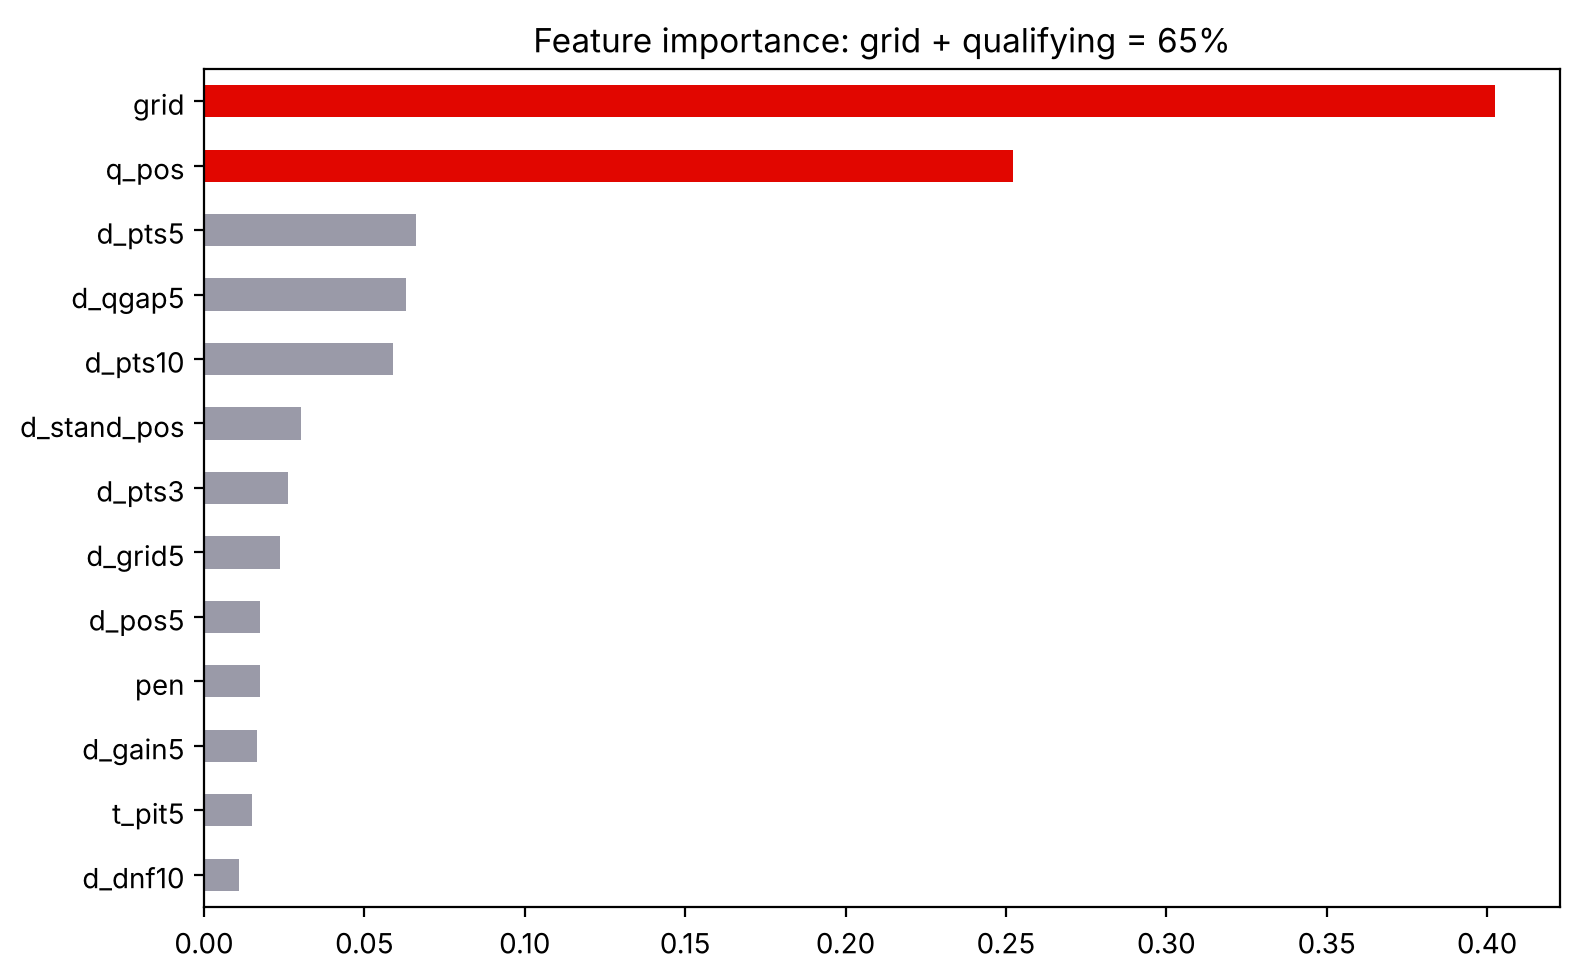

In [17]:
imp = pd.Series(np.mean([m.feature_importances_ for m in models], axis=0), index=FEATURES).sort_values()
ax = imp.plot.barh(figsize=(8, 5), color=["#E10600" if f in ("grid", "q_pos") else "#9a9aa8" for f in imp.index])
ax.set_title("Feature importance: grid + qualifying = {:.0%}".format(imp[["grid", "q_pos"]].sum()))
plt.tight_layout(); plt.show()

## Step 6 · Lineup Search & Budget Evaluation

In [18]:
pool = out.dropna(subset=["price"]).reset_index(drop=True)        # 21 drivers with a price
rows = []
for a, b, c in itertools.combinations(range(len(pool)), 3):         # every 3-driver lineup
    t = pool.loc[[a, b, c]]
    rows.append((" + ".join(t.driver.str.split().str[-1]), t.price.sum(), t.expected_points.sum(),
                 t.expected_points.sum() / t.price.sum()))
lineups = pd.DataFrame(rows, columns=["lineup", "total_price", "expected_points", "team_ratio"])
lineups = lineups.sort_values("team_ratio", ascending=False).reset_index(drop=True)
print("Lineups tested:", len(lineups))
print("Top 5 lineups by predicted team ratio:")
display(lineups.head(5).round(2))

Lineups tested: 1330
Top 5 lineups by predicted team ratio:


,lineup,total_price,expected_points,team_ratio
0,Antonelli + Lindblad + Lawson,4.0,25.85,6.46
1,Antonelli + Lindblad + Colapinto,4.0,23.92,5.98
2,Antonelli + Lindblad + Bearman,4.0,22.27,5.57
3,Antonelli + Lawson + Colapinto,4.0,20.96,5.24
4,Antonelli + Lawson + Bearman,4.0,19.31,4.83


In [19]:
# budget evaluation: best lineup in each budget range
bands = [(0, 4), (5, 10), (11, 20), (21, 40), (80, 200)]
best = pd.DataFrame([lineups[lineups.total_price.between(lo, hi)].iloc[0].rename(f"${lo}-{hi}M") for lo, hi in bands])
print("Spending more always lowers the ratio:")
display(best.round(2))

Spending more always lowers the ratio:


,lineup,total_price,expected_points,team_ratio
$0-4M,Antonelli + Lindblad + Lawson,4.0,25.85,6.46
$5-10M,Antonelli + Lindblad + Bortoleto,5.0,22.73,4.55
$11-20M,Antonelli + Hadjar + Bottas,12.0,27.16,2.26
$21-40M,Antonelli + Hadjar + Norris,37.0,39.83,1.08
$80-200M,Antonelli + Norris + Verstappen,102.0,48.86,0.48


## Result

| Lineup | Price | Predicted ratio | Pre-race rank | Actual ratio |
|---|---|---|---|---|
| Antonelli + Lindblad + Lawson (model's #1, submitted Nov 21) | $4M | 6.46 | 1 of 1,330 | 3.0 |
| Antonelli + Lindblad + Colapinto (final lineup) | $4M | 5.98 | 2 of 1,330 | 5.0 |

Actual race: Antonelli P4 (12 pts), Colapinto P6 (8 pts), Lawson P15 (0), Lindblad DNF (0).

**Limitations.** Features, model settings and the training window were all chosen on the same 2026 Rounds 6–20 backtest, so the backtest RMSE is somewhat optimistic. One race is a single draw: a ratio of 5.0 vs 3.0 says little about model quality on its own.